In [2]:
import torch
import argparse
from registry import build_model
from utils.trainer_utils import *
from reference.reference_burgers import burgers_solution
from main import *
from types import SimpleNamespace


In [3]:
"""Full-trajectory metrics on existing Cartesian model outputs; no re-query."""
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SHOCK_X_BOUNDS = (0.0, 2.0)
SHOCK_MERGE_TIME = 0.5
SHOCK_SEARCH_RADIUS = 0.20
SHOCK_CELL_FRACTION = 0.95
SHOCK_MIN_WIDTH_CELLS = 4
SHOCK_BAND_HALF_WIDTH = 0.01

def shock_branches(t):
    if t < SHOCK_MERGE_TIME:
        return [('incoming',2*t,2.5,1.5), ('initial',.5+t,1.5,.5)]
    return [('merged',1.5*t+.25,2.5,.5)]

def exact_shock_profile(x,t):
    if t < SHOCK_MERGE_TIME:
        return np.where(x<2*t,2.5,np.where(x<.5+t,1.5,.5))
    return np.where(x<1.5*t+.25,2.5,.5)

def downward_crossings(x,u,level):
    """Only sign-changing downward crossings; linear interpolation, no smoothing."""
    z=np.asarray(u)-level
    nz=np.flatnonzero(z!=0)
    roots=[]
    for i,j in zip(nz[:-1],nz[1:]):
        if z[i]>0 and z[j]<0:
            root=(x[i+1]+x[j-1])/2 if j>i+1 else x[i]-z[i]*(x[j]-x[i])/(z[j]-z[i])
            roots.append(float(root))
    return np.asarray(roots)

def shock_grid(coords,values):
    def array(a):
        return a.detach().cpu().numpy() if hasattr(a,'detach') else np.asarray(a)
    c=array(coords).reshape(-1,2);v=array(values).reshape(-1)
    if len(c)!=len(v):raise ValueError('Physical coordinate/value count mismatch')
    x=np.unique(c[:,0]);t=np.unique(c[:,1]);order=np.lexsort((c[:,1],c[:,0]))
    if len(x)*len(t)!=len(c):raise ValueError('Expected complete physical Cartesian grid')
    expected=np.stack(np.meshgrid(x,t,indexing='ij'),axis=-1).reshape(-1,2)
    if not np.allclose(c[order],expected):raise ValueError('Invalid Cartesian coordinates')
    return x.astype(float),t.astype(float),v[order].reshape(len(x),len(t)).astype(float)

def trajectory_weights(t):
    if len(t)<2 or not np.all(np.diff(t)>0):raise ValueError('Need at least two increasing time samples')
    w=np.zeros(len(t));w[:-1]+=np.diff(t)/2;w[1:]+=np.diff(t)/2
    return w

def measure_shock_trajectories(x,t,prediction,reference=None):
    x=np.asarray(x,float);t=np.asarray(t,float);u=np.asarray(prediction,float)
    if u.shape!=(len(x),len(t)) or not np.isfinite(u).all():raise ValueError('Invalid prediction grid')
    if not np.all(np.diff(x)>0) or len(x)<3:raise ValueError('Invalid spatial grid')
    if not np.isclose(x[0],SHOCK_X_BOUNDS[0],atol=1e-6) or not np.isclose(x[-1],SHOCK_X_BOUNDS[1],atol=1e-6):
        raise ValueError('Expected Burgers domain [0,2]')
    if t[0]<0 or t[-1]>1+1e-6:raise ValueError('Expected Burgers time range within [0,1]')
    dx=float(np.max(np.diff(x)));weights=trajectory_weights(t);rows=[]
    for k,time in enumerate(t):

        time=float(SHOCK_MERGE_TIME if abs(time-SHOCK_MERGE_TIME)<1e-7 else time)
        branches=shock_branches(time)
        if reference is not None:
            expected=exact_shock_profile(x,time)
            away=np.ones(len(x),bool)
            for _,xs,_,_ in branches:away &= abs(x-xs)>2*dx
            if away.any() and not np.allclose(reference[away,k],expected[away],atol=1e-5,rtol=1e-5):
                raise ValueError('burgers_solution does not match the assumed 2.5/1.5/0.5 merging-shock benchmark')
        for name,xs,high,low in branches:
            distances=[abs(xs-other[1])/2 for other in branches if other[0]!=name]
            cell=min([xs-x[0],x[-1]-xs]+distances)
            radius=SHOCK_CELL_FRACTION*cell
            row=dict(branch=name,time=time,time_index=k,time_weight=weights[k],
                exact_x=xs,high_state=high,low_state=low,threshold90=low+.9*(high-low),
                threshold50=(high+low)/2,threshold10=low+.1*(high-low),
                eligible=bool(cell>1e-10),search_radius=max(0.,min(radius,SHOCK_SEARCH_RADIUS)),
                detected=False,midpoint_crossings=0,prediction_x=np.nan,signed_location_error=np.nan,
                location_error=np.nan,width=np.nan,width_valid=False,width_start=np.nan,width_end=np.nan,
                width_underresolved=False,window_underresolved=bool(2*radius<SHOCK_MIN_WIDTH_CELLS*dx),
                status='boundary_or_outside')
            if row['eligible']:
                mids=downward_crossings(x,u[:,k],row['threshold50'])
                mids=mids[abs(mids-xs)<=row['search_radius']]
                row['midpoint_crossings']=len(mids)
                row['status']='midpoint_missing'
                if len(mids):
                    xp=float(mids[np.argmin(abs(mids-xs))])
                    starts=downward_crossings(x,u[:,k],row['threshold90'])
                    ends=downward_crossings(x,u[:,k],row['threshold10'])
                    starts=starts[(starts>=xs-radius)&(starts<xp)]
                    ends=ends[(ends>xp)&(ends<=xs+radius)]
                    valid=bool(len(starts) and len(ends))
                    width=float(ends.min()-starts.max()) if valid else np.nan
                    row.update(detected=True,prediction_x=xp,signed_location_error=xp-xs,
                        location_error=abs(xp-xs),width=width,width_valid=valid,
                        width_start=float(starts.max()) if valid else np.nan,
                        width_end=float(ends.min()) if valid else np.nan,
                        width_underresolved=bool(valid and width<SHOCK_MIN_WIDTH_CELLS*dx),
                        status='ok' if valid else 'width_threshold_missing')
            rows.append(row)
    return pd.DataFrame(rows)

def summarize_shock_rows(df):
    eligible=df[df.eligible];located=eligible[eligible.detected];widths=eligible[eligible.width_valid]
    total=float(eligible.time_weight.sum())
    def weighted(frame,key):
        return float(np.average(frame[key],weights=frame.time_weight)) if len(frame) else np.nan
    return dict(eligible_samples=len(eligible),boundary_or_outside_samples=len(df)-len(eligible),
        detected_samples=len(located),width_valid_samples=len(widths),
        trajectory_time_measure=total,
        detection_rate=float(located.time_weight.sum()/total) if total else np.nan,
        width_valid_rate=float(widths.time_weight.sum()/total) if total else np.nan,
        location_mae=weighted(located,'location_error'),
        location_rmse=float(np.sqrt(weighted(located.assign(squared=located.location_error**2),'squared'))),
        location_max=float(located.location_error.max()) if len(located) else np.nan,
        width_mean=weighted(widths,'width'),
        width_max=float(widths.width.max()) if len(widths) else np.nan,
        multiple_crossing_rate=weighted(eligible.assign(multiple=(eligible.midpoint_crossings>1).astype(float)),'multiple'),
        width_underresolved_rate=weighted(widths,'width_underresolved'),
        window_underresolved_rate=weighted(eligible,'window_underresolved'))

def save_burgers_shock_metrics(coords,u_pred,u_ref,save_dir):
    x,t,pred=shock_grid(coords,u_pred);_,_,ref=shock_grid(coords,u_ref)
    detail=measure_shock_trajectories(x,t,pred,ref)
    summary=summarize_shock_rows(detail)
    folder=Path(save_dir)/'shock_trajectory';folder.mkdir(parents=True,exist_ok=True)
    detail.to_csv(folder/'shock_details.csv',index=False)
    by_branch=pd.DataFrame([dict(branch=name,**summarize_shock_rows(group)) for name,group in detail.groupby('branch',sort=False)])
    by_branch.to_csv(folder/'shock_branch_summary.csv',index=False)
    pd.DataFrame([summary]).to_csv(folder/'shock_global_summary.csv',index=False)
    settings=dict(x_bounds=SHOCK_X_BOUNDS,merge_time=SHOCK_MERGE_TIME,
        search_radius=SHOCK_SEARCH_RADIUS,cell_fraction=SHOCK_CELL_FRACTION,
        minimum_width_cells=SHOCK_MIN_WIDTH_CELLS,dx=float(np.max(np.diff(x))),
        dt_max=float(np.max(np.diff(t))),time_start=float(t[0]),time_end=float(t[-1]),
        aggregation='trapezoidal time weights per active shock branch; conditional errors plus coverage',
        location='horizontal x distance at fixed t; not Euclidean distance in (x,t)',
        width='physical-state 10-90 percent width, exact width=0; no relative width error',
        merge='one merged branch at t=0.5; pre-merge branch windows remain disjoint',
        crossings='nearest downward midpoint crossing inside fixed reference window; counts retained',
        prediction='unchanged full-grid model evaluation, no smoothing or dense model re-query')
    (folder/'shock_settings.json').write_text(json.dumps(settings,indent=2),encoding='utf-8')
    fig,axes=plt.subplots(1,3,figsize=(15,4.5),dpi=180)
    for name,group in detail.groupby('branch',sort=False):
        axes[0].plot(group.exact_x,group.time,'-',label=f'{name} exact')
        axes[0].plot(group.prediction_x,group.time,'--',label=f'{name} predicted')
        axes[1].plot(group.time,group.location_error,label=name)
        axes[2].plot(group.time,group.width,label=name)
    axes[0].set(xlabel='x',ylabel='t',title='Full shock trajectory',xlim=SHOCK_X_BOUNDS)
    axes[1].set(xlabel='t',ylabel='Absolute location error',title='Position error along trajectory')
    axes[2].set(xlabel='t',ylabel='10-90% width',title='Transition width (exact: zero)')
    for ax in axes:ax.legend(fontsize=8);ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(folder/'shock_trajectory_metrics.png');plt.close(fig)
    print(f'Shock trajectory: location MAE={summary["location_mae"]:.4e}, width={summary["width_mean"]:.4e}, detection={summary["detection_rate"]:.3f}, width-valid={summary["width_valid_rate"]:.3f}')
    return {'shock_'+key:value for key,value in summary.items()}

def measure_shock_band(x, t, prediction, reference):
    """Union of fixed-x bands around exact interior shocks at each time."""
    if not np.isfinite(SHOCK_BAND_HALF_WIDTH) or SHOCK_BAND_HALF_WIDTH <= 0:
        raise ValueError('SHOCK_BAND_HALF_WIDTH must be finite and positive')
    error = prediction - reference
    mask = np.zeros(error.shape, dtype=bool)
    for k, time in enumerate(t):
        time = float(SHOCK_MERGE_TIME if abs(time-SHOCK_MERGE_TIME) < 1e-7 else time)
        for _, position, _, _ in shock_branches(time):
            if x[0] < position < x[-1]:
                mask[:, k] |= np.abs(x-position) <= SHOCK_BAND_HALF_WIDTH
    rows = []
    for k, time in enumerate(t):
        values = error[mask[:, k], k]
        rows.append(dict(time_index=k, time=float(time),
            shock_band_point_count=int(values.size),
            shock_band_rmse=float(np.sqrt(np.mean(values**2))) if values.size else np.nan))
    values = error[mask]
    summary = dict(band_point_count=int(values.size),
        band_rmse=float(np.sqrt(np.mean(values**2))) if values.size else np.nan)
    return pd.DataFrame(rows), summary

def save_burgers_shock_band_metrics(coords, u_pred, u_ref, save_dir):
    x, t, pred = shock_grid(coords, u_pred)
    _, _, ref = shock_grid(coords, u_ref)
    timewise, summary = measure_shock_band(x, t, pred, ref)
    folder = Path(save_dir) / 'shock_trajectory'
    folder.mkdir(parents=True, exist_ok=True)
    timewise.to_csv(folder / 'shock_band_timewise.csv', index=False)
    pd.DataFrame([{'shock_'+k: v for k, v in summary.items()}]).to_csv(
        folder / 'shock_band_global_summary.csv', index=False)
    settings_path = folder / 'shock_settings.json'
    settings = json.loads(settings_path.read_text(encoding='utf-8'))
    settings.update(band_half_width=SHOCK_BAND_HALF_WIDTH,
        band_distance='abs(x-x_exact(t)) at fixed t; not space-time distance',
        band_region='union over exact interior shocks; overlaps counted once; boundary-only shocks excluded',
        band_aggregation='sqrt(sum of squared errors / total selected Cartesian grid points across all times)',
        band_detection='independent of predicted shock detection')
    settings_path.write_text(json.dumps(settings, indent=2), encoding='utf-8')
    fig, ax = plt.subplots(figsize=(7, 4.5), dpi=180)
    ax.plot(t, timewise['shock_band_rmse'], linewidth=2)
    ax.set(xlabel='Time', ylabel='Shock-band RMSE')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(folder / 'shock_band_rmse_timewise.png', bbox_inches='tight')
    plt.close(fig)
    return {'shock_'+k: v for k, v in summary.items()}


In [4]:
def save_sa_weight_distribution(method_name, seed, checkpoint_path, save_dir, vmin=None, vmax=None):
    checkpoint_path = Path(checkpoint_path)
    weight_path = checkpoint_path.with_name(f"{checkpoint_path.stem}_sa_weights.pt")

    snapshot = torch.load(weight_path, map_location="cpu", weights_only=False)

    group = snapshot["groups"]["pde"]
    coords = group["coords"].detach().cpu().numpy().reshape(-1, 2)
    parameters = group["parameter"].detach().cpu().numpy().reshape(-1)

    x_values, x_indices = np.unique(coords[:, 0], return_inverse=True)
    t_values, t_indices = np.unique(coords[:, 1], return_inverse=True)

    nx = len(x_values)
    nt = len(t_values)

    weight_grid = np.empty((nt, nx), dtype=parameters.dtype)
    weight_grid[t_indices, x_indices] = parameters

    save_dir = Path(save_dir) / "sa_weights"
    save_dir.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(figsize=(6, 5))

    im = ax.imshow(
        weight_grid,
        origin="lower",
        extent=[
            float(x_values.min()),
            float(x_values.max()),
            float(t_values.min()),
            float(t_values.max()),
        ],
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
    )

    colorbar = fig.colorbar(im, ax=ax)
    colorbar.ax.tick_params(labelsize=18)

    ax.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.tick_params(axis="both", labelsize=18)

    ax.set_xlabel("x", fontsize=18)
    ax.set_ylabel("t", fontsize=18)

    fig.tight_layout()

    figure_path = save_dir / "sa_parameter_distribution.png"
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

    np.savez_compressed(
        save_dir / "sa_parameter_distribution.npz",
        x=x_values,
        t=t_values,
        parameter=weight_grid,
        checkpoint=str(checkpoint_path),
        weight_file=str(weight_path),
    )

    print(f"[Saved] {method_name}, seed={seed}: {figure_path}")


In [5]:
def save_ntk_coefficient_history(
    method_name,
    seed,
    experiment_dir,
    save_dir,
    ntk_update_every,
    ylim=None,
):
    analysis_path = (Path(experiment_dir)/"analysis"/f"seed{seed}"/"analysis.pt")

    analysis = torch.load(analysis_path, map_location="cpu", weights_only=False)

    coefficient_keys = {
        "pde": "ntk_pde_coefficient",
        "ini1": "ntk_ini1_coefficient",
        "ini2": "ntk_ini2_coefficient",
        "bc": "ntk_bc_coefficient",
    }

    rows = []

    for epoch, record in sorted(
        analysis["epochs"].items(),
        key=lambda item: int(item[0]),
    ):
        epoch = int(epoch)

        if epoch % ntk_update_every != 0:
            continue

        if not all(key in record for key in coefficient_keys.values()):
            continue

        row = {"epoch": epoch}

        for group, key in coefficient_keys.items():
            value = record[key]
            row[group] = (
                float(value.detach().cpu().item())
                if torch.is_tensor(value)
                else float(value)
            )

        rows.append(row)

    if not rows:
        raise ValueError(
            f"No complete NTK coefficient history found in {analysis_path}. "
            "Required groups: pde, ini1, ini2, bc."
        )

    history_df = pd.DataFrame(rows)

    save_dir = Path(save_dir) / "ntk_weights"
    save_dir.mkdir(parents=True, exist_ok=True)

    history_df.to_csv(save_dir/"ntk_coefficient_history.csv", index=False)

    colors = plt.get_cmap("tab10").colors

    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)

    for group, color, label in [
        ("pde", colors[0], r"$\alpha_{1}$"),
        ("ini1", colors[1], r"$\alpha_{2}$"),
        ("ini2", colors[2], r"$\alpha_{3}$"),
        ("bc", colors[3], r"$\alpha_{4}$"),
    ]:
        ax.plot(
            history_df["epoch"],
            history_df[group],
            color=color,
            linewidth=2,
            label=label,
        )

    ax.set_xlabel("Epoch", fontsize=18)
    ax.set_ylabel(r"$\alpha$", fontsize=18)
    ax.tick_params(axis="both", labelsize=18)

    if ylim is not None:
        ax.set_ylim(*ylim)

    ax.legend(loc="upper right", fontsize=18)

    fig.tight_layout()

    figure_path = save_dir / "ntk_coefficient_history.png"
    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
    )
    plt.close(fig)

    print(f"[Saved] {method_name}, seed={seed}: {figure_path}")

    return history_df


In [6]:
device = torch.device("cuda")

def build_args():
    args = SimpleNamespace()
    args.model_name = cfg["model_name"]
    args.eval_h_x = 1/100
    args.eval_h_t = 1/100

    args.no_sharp_const = False
    args.sharp_const = 1.0

    if args.model_name == "PINN":
        args.layers = cfg["layers"]
        args.activation = cfg["activation"]
    elif args.model_name == "PINN_SlopeLimiter":
        args.layers = cfg["layers"]
        args.activation = cfg["activation"]
        args.input_dim = cfg["input_dim"]
        args.embed_dim = cfg["embed_dim"]
        args.sharp_const = cfg["sharp_const"]
        args.fourier_scale = cfg["fourier_scale"]
    elif args.model_name == "BurgersSLFormerFixedSharpAnalysis_Random":
        args.embed_dim = cfg["embed_dim"]
        args.num_heads = cfg["num_heads"]
        args.depth = cfg["depth"]
        args.fourier_scale = cfg["fourier_scale"]
        args.h_x = cfg["virtual_dx"]
    else:
        args.embed_dim = cfg["embed_dim"]
        args.num_heads = cfg["num_heads"]
        args.depth = cfg["depth"]
        args.fourier_scale = cfg["fourier_scale"]

    return args

METHODS = {
    "SLFormer": {
        "model_name": "BurgersSLFormerFixedSharpAnalysis",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 1,
        "checkpoint_root": "runs/results_multi(burgers)",
    },
    "SLFormer_random": {
        "model_name": "BurgersSLFormerFixedSharpAnalysis_Random",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 1,
        "virtual_dx": 1/64,
        "checkpoint_root": "runs/results_multi_random(burgers)",
    },
    "SLFormer_NoSlope": {
        "model_name": "BurgersSLFormerFixedSharpAnalysis_NoSlope",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 1,
        "checkpoint_root": "runs/results_multi_NoSlope(burgers)",
    },
    "SLFormer_Single_NoSlope": {
        "model_name": "BurgersSLFormer_Single_NoSlope",
        "embed_dim": 96,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 1,
        "checkpoint_root": "runs/results_single_NoSlope(burgers)",
    },
    "SLFormer_Superbee": {
        "model_name": "BurgersSLFormerFixedSharpAnalysis_Superbee",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 1,
        "checkpoint_root": "runs/results_multi_superbee(burgers)",
    },
    "SLFormer_MC": {
        "model_name": "BurgersSLFormerFixedSharpAnalysis_MC",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 1,
        "checkpoint_root": "runs/results_multi_MC(burgers)",
    },
    "SLFormer_Single": {
        "model_name": "BurgersSLFormerFixedSharpAnalysis_Single",
        "embed_dim": 96,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 1,
        "checkpoint_root": "runs/results_single(burgers)",
    },
    "Conventional": {
        "model_name": "PINN",
        "layers": [2, 50, 50, 50, 50, 50, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/results_conventional(burgers)",
    },
    "Causal": {
        "model_name": "PINN",
        "layers": [2, 50, 50, 50, 50, 50, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/results_causal(burgers)",
    },
    "RBA": {
        "model_name": "PINN",
        "layers": [2, 50, 50, 50, 50, 50, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/results_rba(burgers)",
    },
    "BRDR": {
        "model_name": "PINN",
        "layers": [2, 50, 50, 50, 50, 50, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/results_brdr(burgers)",
    },
    "NTK": {
        "model_name": "PINN",
        "layers": [2, 50, 50, 50, 50, 50, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/results_NTK(burgers)",
    },
    "SA": {
        "model_name": "PINN",
        "layers": [2, 50, 50, 50, 50, 50, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/results_SA(burgers)",
    },
    "aSA": {
        "model_name": "PINN",
        "layers": [2, 50, 50, 50, 50, 50, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/results_aSA(burgers)",
    },
}

results_by_method = {}

output_root = Path("evaluation/burgers")
output_root.mkdir(parents=True, exist_ok=True)

for method_name, cfg in METHODS.items():

    method_dir = (output_root / method_name)
    method_dir.mkdir(parents=True, exist_ok=True)

    args = build_args()

    eval_data = make_burgers_data(
        h_x=args.eval_h_x,
        h_t=args.eval_h_t,
        device=device,
    )
    root = Path(cfg["checkpoint_root"])
    experiment_dirs = sorted(root.glob("*_new"))
    if len(experiment_dirs) == 0:
        raise RuntimeError(f"No folder ending with '_new' found in {root}")
    latest_dir = experiment_dirs[-1]

    for seed in [1, 2, 3, 4, 5]:

        model = build_model(args).to(device)

        checkpoint_dir = latest_dir / "checkpoints" / f"seed{seed}"
        if "checkpoint_name" in cfg:
            checkpoint_path = checkpoint_dir / cfg["checkpoint_name"]
        elif method_name.lower() in {"sa", "ntk", "asa"}:
            checkpoint_path = checkpoint_dir / "last_lbfgs.pth"
        else:
            lbfgs_path = checkpoint_dir / "lbfgs_best_loss.pth"
            adam_path = checkpoint_dir / "best_loss.pth"
            checkpoint_path = lbfgs_path if lbfgs_path.is_file() else adam_path
        if not checkpoint_path.is_file():
            raise FileNotFoundError(
                f"Checkpoint not found: {checkpoint_path}. "
                "Check checkpoint_root and checkpoint_name; SA/NTK/aSA require last_lbfgs.pth."
            )
        print(f"[{method_name} | seed{seed}] Loading checkpoint: {checkpoint_path}")
        checkpoint = torch.load(checkpoint_path, map_location=device)
        state_dict = checkpoint["model_state"] if isinstance(checkpoint, dict) and "model_state" in checkpoint else checkpoint
        model.load_state_dict(state_dict, strict=True)

        model.eval()

        with torch.no_grad():
            coords_ghost, u_pred, aux = evaluate_model_on_inner_grid(
                model=model,
                data=eval_data,
                sharp_const=(
                    None
                    if args.no_sharp_const
                    else args.sharp_const
                ),
            )

        coords = eval_data["domain_coords_inner"]
        u_ref = burgers_solution(coords)
        rel_l2 = relative_l2_error(u_pred, u_ref)

        print(f"Relative L2 Error : {rel_l2:.4e}")

        save_dir = method_dir / f"seed{seed}"
        save_dir.mkdir(parents=True, exist_ok=True)

        if method_name in {"SA", "aSA"}:
            save_sa_weight_distribution(
                method_name=method_name,
                seed=seed,
                checkpoint_path=checkpoint_path,
                save_dir=save_dir,
                vmin=10.4,
                vmax=12.0,
            )
        if method_name in {"NTK", "aSA"}:
            save_ntk_coefficient_history(
                method_name=method_name,
                seed=seed,
                experiment_dir=latest_dir,
                save_dir=save_dir,
                ntk_update_every=2500,
            )
        shock_metrics = save_burgers_shock_metrics(coords, u_pred, u_ref, save_dir)
        shock_metrics.update(save_burgers_shock_band_metrics(
            coords, u_pred, u_ref, save_dir))
        torch.save({
            "coords": coords.detach().cpu(),
            "u_pred": u_pred.detach().cpu(),
            "u_ref": u_ref.detach().cpu(),
            "checkpoint": str(checkpoint_path),
            "shock_metrics": shock_metrics,
        }, save_dir / "evaluation_shock.pt")

        save_prediction_burgers_plot_test(
            coords,
            u_pred,
            eval_data,
            save_dir / "prediction.png",
            title="Prediction",
        )

        save_prediction_burgers_plot_test(
            coords,
            u_ref,
            eval_data,
            save_dir.resolve() / "reference.png",
            title="Reference",
        )

        save_error_contour_burgers_plot_test(
            coords,
            u_pred,
            u_ref,
            eval_data,
            save_dir / "error.png",
            title="Error",
        )

        if method_name not in results_by_method:
            results_by_method[method_name] = []

        results_by_method[method_name].append(
            {
                "method": method_name,
                "seed": seed,
                "checkpoint": str(checkpoint_path),
                "relative_l2": float(rel_l2),
                **shock_metrics,
            }
        )


[SLFormer | seed1] Loading checkpoint: runs\results_multi(burgers)\20260802_025922_BurgersSLFormerFixedSharpAnalysis_new\checkpoints\seed1\lbfgs_best_loss.pth


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_680\1917192607.py:181: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=devi

Relative L2 Error : 7.5910e-02
Shock trajectory: location MAE=1.0942e-02, width=9.1297e-02, detection=0.953, width-valid=0.738
[SLFormer | seed2] Loading checkpoint: runs\results_multi(burgers)\20260802_025922_BurgersSLFormerFixedSharpAnalysis_new\checkpoints\seed2\lbfgs_best_loss.pth


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_680\1917192607.py:181: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=devi

Relative L2 Error : 1.0323e-01
Shock trajectory: location MAE=2.0549e-02, width=6.2615e-02, detection=0.906, width-valid=0.705
[SLFormer | seed3] Loading checkpoint: runs\results_multi(burgers)\20260802_025922_BurgersSLFormerFixedSharpAnalysis_new\checkpoints\seed3\lbfgs_best_loss.pth
Relative L2 Error : 7.3159e-02


...

[Saved] aSA, seed=3: evaluation\burgers\aSA\seed3\ntk_weights\ntk_coefficient_history.png
Shock trajectory: location MAE=2.3821e-02, width=6.2420e-02, detection=0.926, width-valid=0.638
[aSA | seed4] Loading checkpoint: runs\results_aSA(burgers)\20261020_213706_PINN_new\checkpoints\seed4\last_lbfgs.pth
Relative L2 Error : 1.0634e-01
[Saved] aSA, seed=4: evaluation\burgers\aSA\seed4\sa_weights\sa_parameter_distribution.png


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_680\1917192607.py:181: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=devi

[Saved] aSA, seed=4: evaluation\burgers\aSA\seed4\ntk_weights\ntk_coefficient_history.png
Shock trajectory: location MAE=1.6982e-02, width=8.7133e-02, detection=0.913, width-valid=0.577
[aSA | seed5] Loading checkpoint: runs\results_aSA(burgers)\20261020_213706_PINN_new\checkpoints\seed5\last_lbfgs.pth
Relative L2 Error : 1.2852e-01
[Saved] aSA, seed=5: evaluation\burgers\aSA\seed5\sa_weights\sa_parameter_distribution.png


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_680\1917192607.py:181: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=devi

[Saved] aSA, seed=5: evaluation\burgers\aSA\seed5\ntk_weights\ntk_coefficient_history.png
Shock trajectory: location MAE=2.2898e-02, width=1.1941e-01, detection=0.893, width-valid=0.577


In [7]:

all_results = []
all_summaries = []
for method_name, records in results_by_method.items():
    if not records:
        continue
    method_dir = output_root / method_name
    method_dir.mkdir(parents=True, exist_ok=True)
    results_df = pd.DataFrame(records)
    results_df.to_csv(method_dir / 'results.csv', index=False)
    numeric = ['relative_l2'] + [name for name in results_df.columns
        if name.startswith('shock_') and pd.api.types.is_numeric_dtype(results_df[name])]
    summary_df = results_df.groupby('method', sort=False).agg(
        {name: ['mean', 'std', 'count'] for name in numeric})
    summary_df.columns = [f'{name}_{stat}' for name, stat in summary_df.columns]
    summary_df = summary_df.reset_index()
    summary_df.to_csv(method_dir / 'summary.csv', index=False)
    print(f'\n{method_name}')
    print(results_df.to_string(index=False, float_format=lambda v: f'{v:.6e}'))
    print(summary_df.to_string(index=False, float_format=lambda v: f'{v:.6e}'))
    all_results.append(results_df)
    all_summaries.append(summary_df)

if all_results:
    pd.concat(all_results, ignore_index=True).to_csv(
        output_root / 'results_all_methods.csv', index=False)
    comparison_df = pd.concat(all_summaries, ignore_index=True)
    comparison_df.to_csv(output_root / 'summary_all_methods.csv', index=False)
    display_columns = ['method', 'relative_l2_mean', 'relative_l2_std',
        'shock_location_mae_mean', 'shock_location_mae_std',
        'shock_location_rmse_mean', 'shock_location_rmse_std',
        'shock_width_mean_mean', 'shock_width_mean_std',
        'shock_detection_rate_mean', 'shock_width_valid_rate_mean',
        'shock_band_rmse_mean', 'shock_band_rmse_std']
    comparison_table = comparison_df[display_columns]
    comparison_table.to_csv(output_root / 'shock_trajectory_comparison.csv', index=False)
    print('\nAll-method comparison (full trajectories; mean over seeds):')
    print(comparison_table.to_string(index=False, float_format=lambda v: f'{v:.6e}'))

    band_frames = []
    for method_name, records in results_by_method.items():
        for record in records:
            path = (output_root / method_name / f"seed{record['seed']}"
                    / 'shock_trajectory' / 'shock_band_timewise.csv')
            frame = pd.read_csv(path)
            band_frames.append(frame.assign(method=method_name, seed=record['seed']))
    if band_frames:
        band_records = pd.concat(band_frames, ignore_index=True)
        band_records.to_csv(output_root / 'shock_band_all_methods_timewise.csv', index=False)
        band_summary = band_records.groupby(['method', 'time_index', 'time'], sort=False).agg(
            {'shock_band_rmse': ['mean', 'std', 'count'],
             'shock_band_point_count': ['mean', 'std', 'count']})
        band_summary.columns = [f'{name}_{stat}' for name, stat in band_summary.columns]
        band_summary = band_summary.reset_index()
        band_summary.to_csv(output_root / 'shock_band_summary_timewise.csv', index=False)
        fig, ax = plt.subplots(figsize=(7, 4.5), dpi=180)
        for method, frame in band_summary.groupby('method', sort=False):
            frame = frame.sort_values('time')
            ax.plot(frame['time'], frame['shock_band_rmse_mean'], label=method)
        ax.set(xlabel='Time', ylabel='Shock-band RMSE (mean over seeds)')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(output_root / 'shock_band_comparison_timewise.png', bbox_inches='tight')
        plt.close(fig)



SLFormer
  method  seed                                                                                                              checkpoint  relative_l2  shock_eligible_samples  shock_boundary_or_outside_samples  shock_detected_samples  shock_width_valid_samples  shock_trajectory_time_measure  shock_detection_rate  shock_width_valid_rate  shock_location_mae  shock_location_rmse  shock_location_max  shock_width_mean  shock_width_max  shock_multiple_crossing_rate  shock_width_underresolved_rate  shock_window_underresolved_rate  shock_band_point_count  shock_band_rmse
SLFormer     1 runs\results_multi(burgers)\20260802_025922_BurgersSLFormerFixedSharpAnalysis_new\checkpoints\seed1\lbfgs_best_loss.pth 7.591023e-02                     150                                  1                     143                        111                   1.490000e+00          9.530201e-01            7.382550e-01        1.094179e-02         1.375495e-02        2.827447e-02      9.129747e-02     2.263

[Saved] evaluation\burgers\paper_figures\Burgers_solution_error_solution_rows4_cols3_part1.png


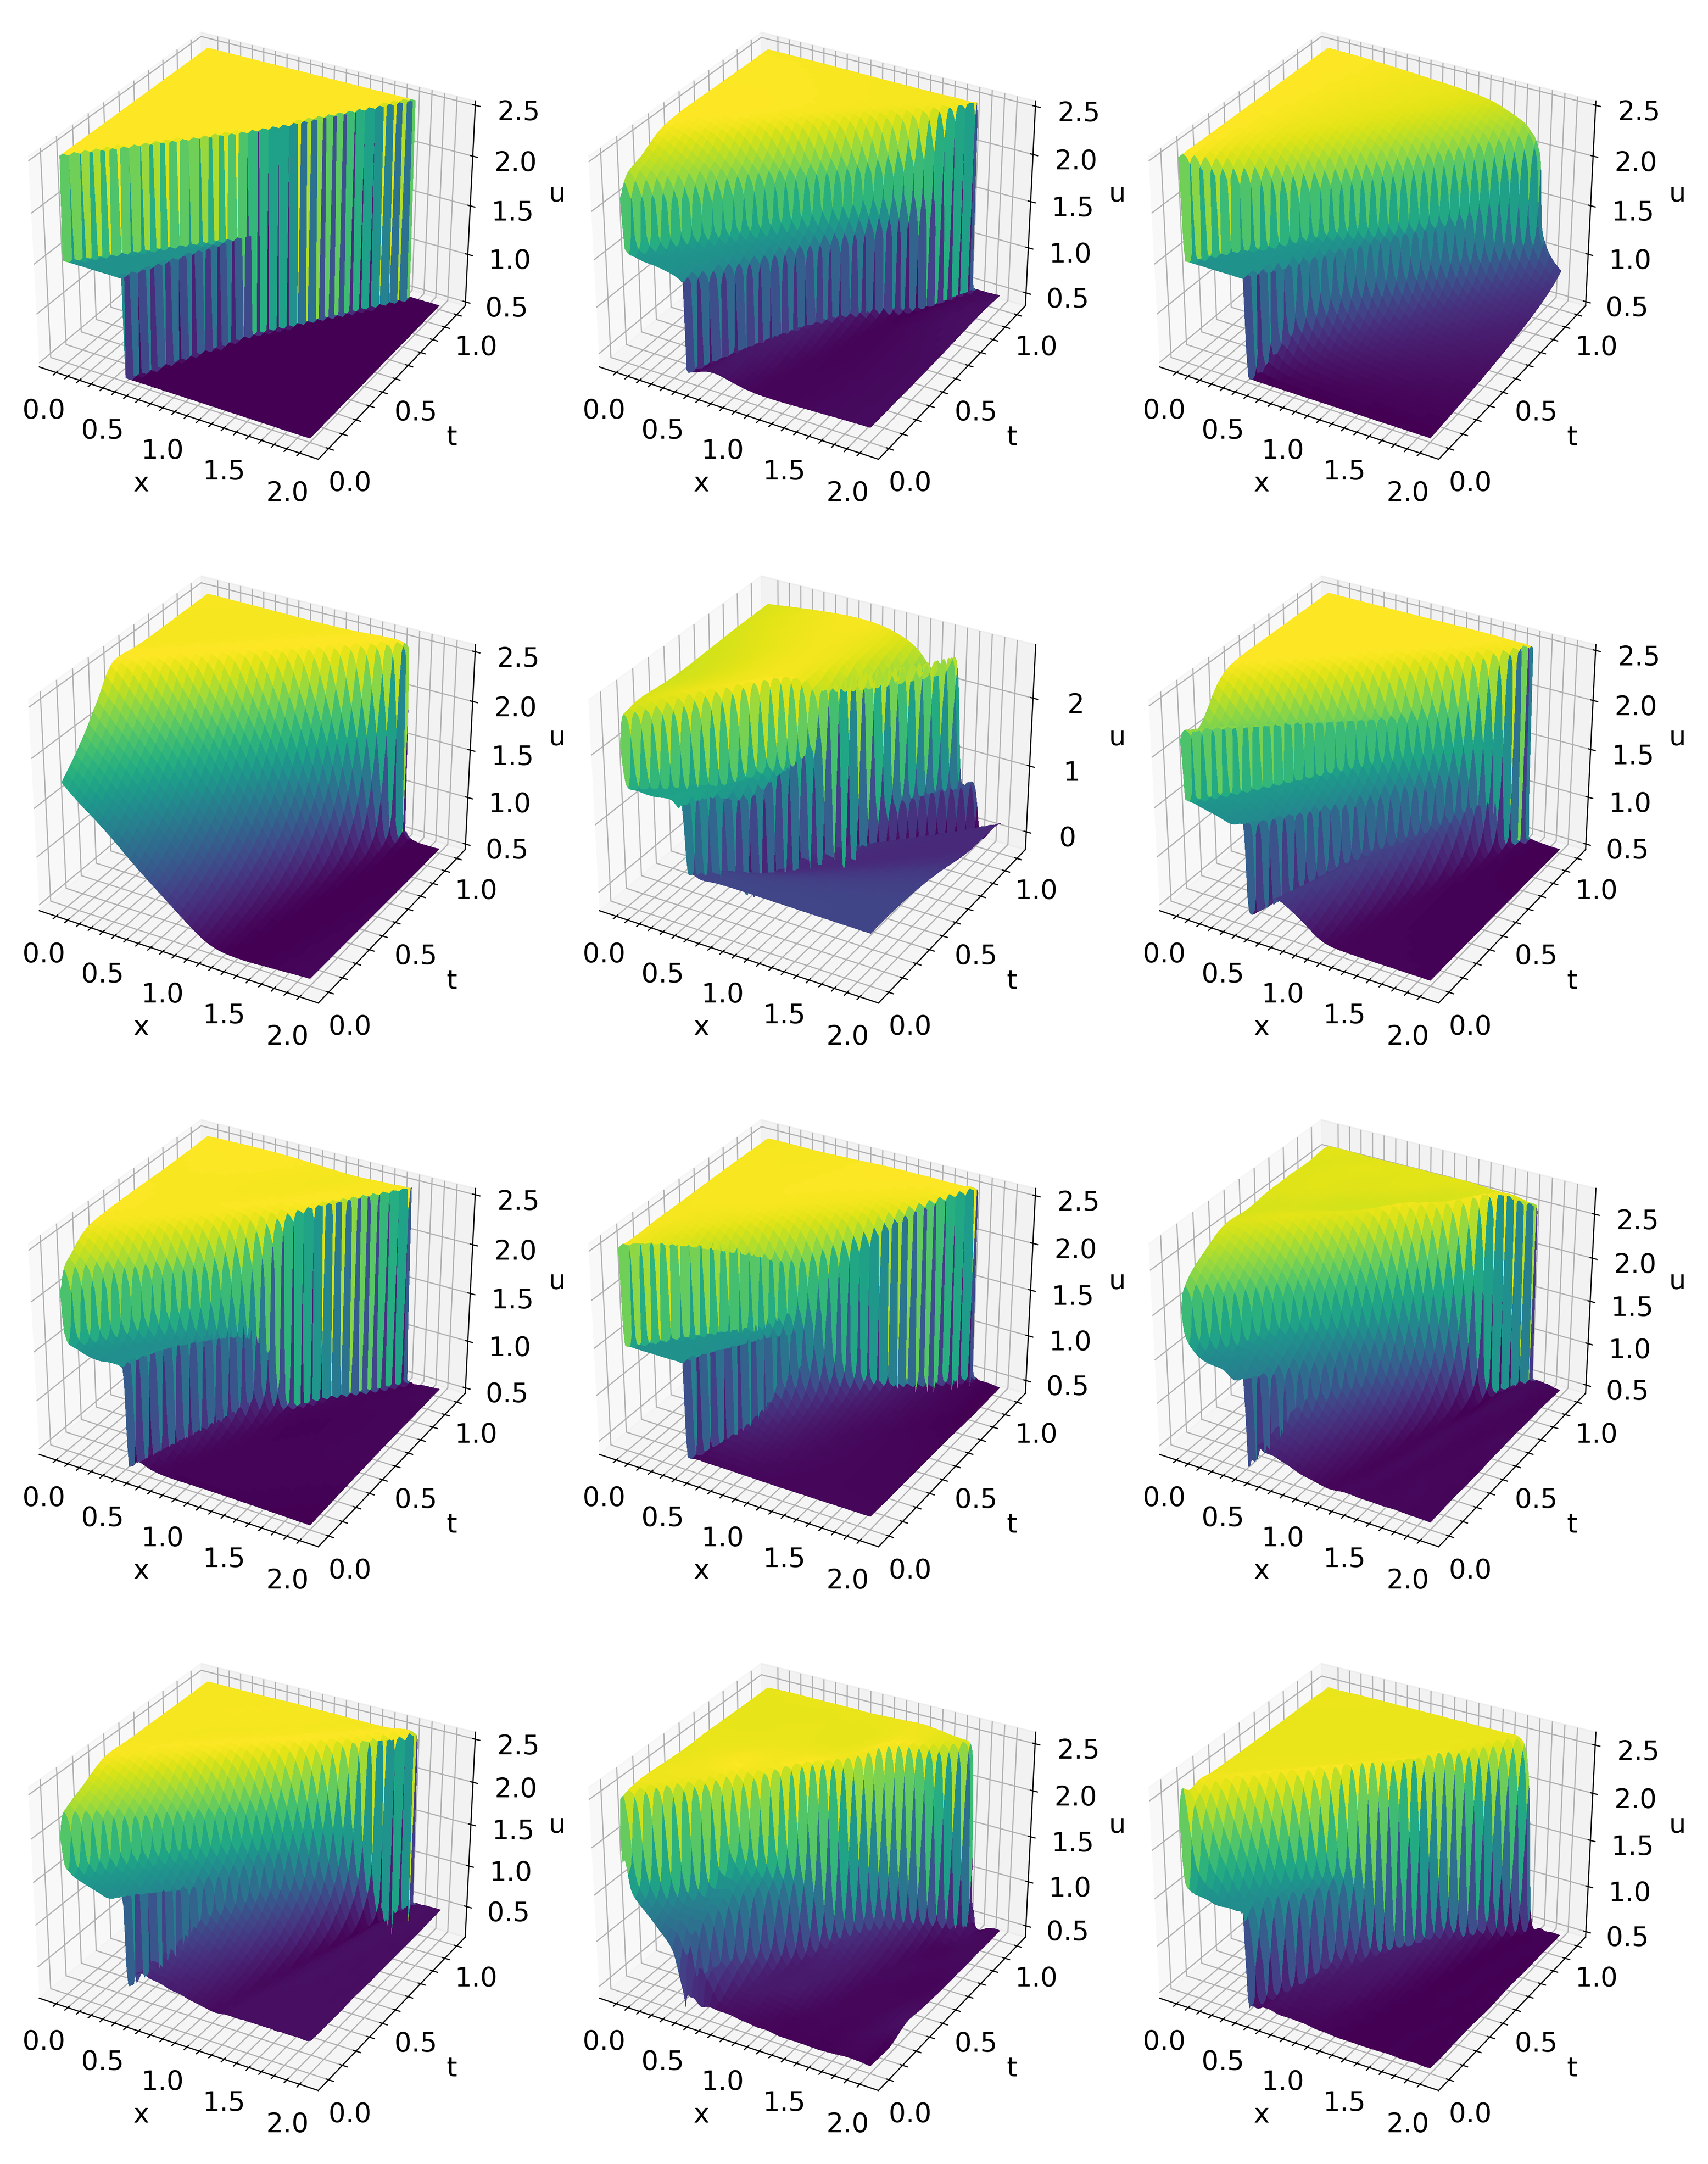

[Saved] evaluation\burgers\paper_figures\Burgers_solution_error_error_rows4_cols3_part1.png


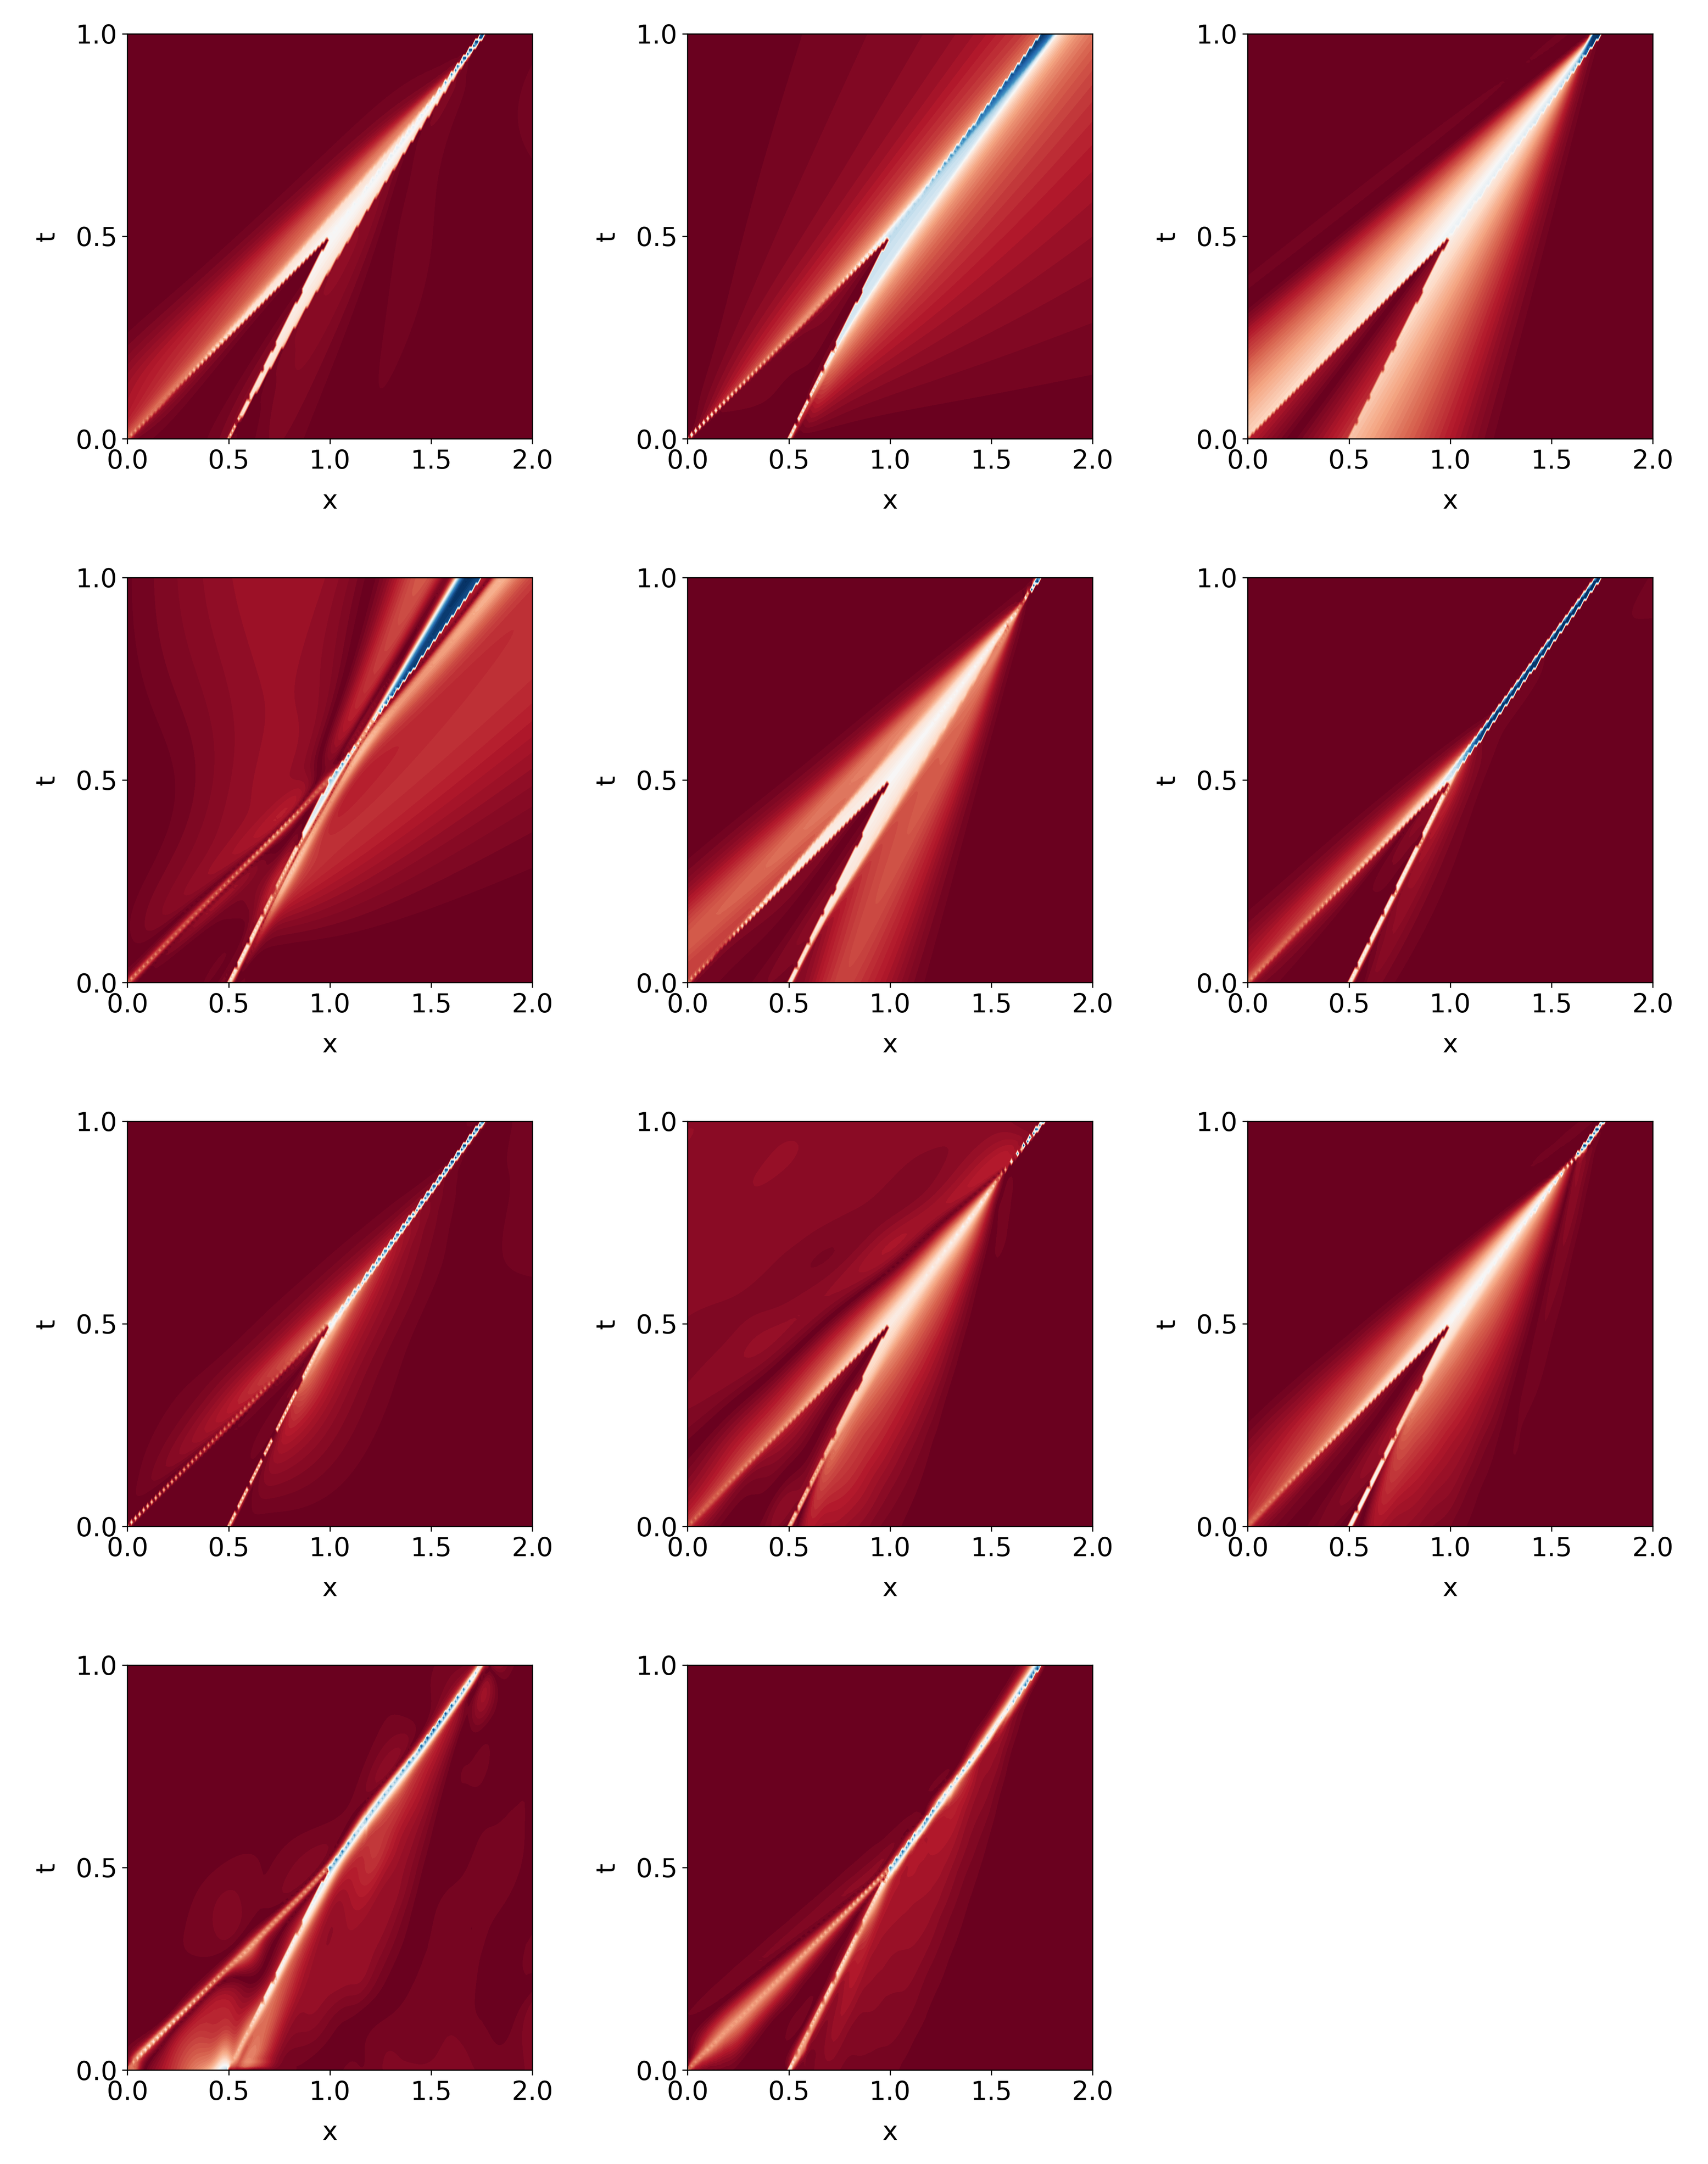

In [18]:
"""Arrange full-domain Burgers 1D solution and error PNGs.
No panel letters, model labels, or time headings are added.
Install if needed: %pip install pillow
"""
from pathlib import Path
import csv
import re
from PIL import Image, ImageChops
from IPython.display import display, Image as NotebookImage

EVALUATION_ROOT = Path("evaluation/burgers")
SEED = None
REFERENCE_METHOD = "Conventional"
KINDS = ("solution", "error")
IMAGE_FILES = {
    "solution": "prediction_surf.png",
    "error": "error.png",
    "reference": "reference_surf.png",
}
OUTPUT_DIR = EVALUATION_ROOT / "paper_figures"
OUTPUT_NAME = "Burgers_selected_seeds"

CELL_WIDTH = 1000
CELL_HEIGHT = 900
COLUMN_GAP = 20
ROW_GAP = 90
OUTER_MARGIN = 35
DPI = 300
ROW_ALIGN = "center"
COLUMN_GAPS = {}
ROW_GAPS = {}
CROP_WHITE_MARGIN = True
WHITE_TOLERANCE = 8
CROP_PADDING = 14
SCALE_MODE = "common"
ALLOW_UPSCALE = False

BLOCK_GAP = 150
PREVIEW_WIDTH = 1200
FILE_PREFIX = "Burgers_solution_error"

def panel(method, kind="solution", seed=None):
    """One full-domain image. seed=None uses SEED, or @ selection if SEED=None."""
    return dict(method=method, kind=kind, seed=seed)

def series(method, kinds=None, seed=None):
    """A row segment; use kinds=(kind,) to assemble one image type only."""
    return [panel(method, kind, seed) for kind in (KINDS if kinds is None else kinds)]

def method_directory(root, name):
    exact = root / name
    if exact.is_dir():
        return exact
    matches = [p for p in root.iterdir() if p.is_dir() and p.name.lower() == name.lower()]
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Method folder missing or ambiguous: {exact}")

def select_seed_directory(root, method, seed=None):
    method_dir = method_directory(root, method)
    candidates = []
    for directory in method_dir.iterdir():
        if not directory.is_dir():
            continue
        match = re.fullmatch(r"seed(\d+)", directory.name.replace("@", "").strip(), flags=re.IGNORECASE)
        if match is None:
            continue
        number = int(match.group(1))
        if (seed is None and "@" in directory.name) or (seed is not None and number == int(seed)):
            candidates.append((number, directory))
    if len(candidates) != 1:
        request = "one @-marked seed folder" if seed is None else f"one folder for seed{seed}"
        raise FileNotFoundError(
            f"Expected {request}; found {len(candidates)}.\n"
            f"Method folder: {method_dir}\nCandidates: {[p.name for _, p in candidates]}"
        )
    return candidates[0]

def find_image(root, method, seed, kind):
    if kind not in IMAGE_FILES:
        raise ValueError(f"Unknown image kind '{kind}'. Expected one of {list(IMAGE_FILES)}.")
    _, seed_dir = select_seed_directory(root, method, seed)
    path = seed_dir / IMAGE_FILES[kind]
    if not path.is_file():
        raise FileNotFoundError(f"Image not found: {path}\nCheck EVALUATION_ROOT and IMAGE_FILES.")
    return path

def load_image(path):
    with Image.open(path) as source:
        rgba = source.convert("RGBA")
        white = Image.new("RGBA", rgba.size, "white")
        white.alpha_composite(rgba)
        image = white.convert("RGB")
    if CROP_WHITE_MARGIN:
        difference = ImageChops.difference(image, Image.new("RGB", image.size, "white"))
        channels = difference.split()
        mask = ImageChops.lighter(ImageChops.lighter(channels[0], channels[1]), channels[2])
        box = mask.point(lambda value: 255 if value > WHITE_TOLERANCE else 0).getbbox()
        if box is None:
            raise ValueError(f"Blank image: {path}")
        x0, y0, x1, y1 = box
        box = (max(0, x0-CROP_PADDING), max(0, y0-CROP_PADDING),
               min(image.width, x1+CROP_PADDING), min(image.height, y1+CROP_PADDING))
        image = image.crop(box)
    return image

def main(root=None, output_dir=None, layout=None):
    root = Path(EVALUATION_ROOT if root is None else root)
    output_dir = Path(OUTPUT_DIR if output_dir is None else output_dir)
    if not root.is_dir():
        raise FileNotFoundError(f"Evaluation root does not exist: {root}\nWorking directory: {Path.cwd()}")
    if layout is None:
        layout = MODEL_ROWS
    if min(CELL_WIDTH, CELL_HEIGHT, DPI) <= 0 or min(COLUMN_GAP, ROW_GAP, OUTER_MARGIN) < 0:
        raise ValueError("Invalid image size, resolution, or spacing.")
    if any(v < 0 for v in (*COLUMN_GAPS.values(), *ROW_GAPS.values())):
        raise ValueError("Gaps must be non-negative.")
    if SCALE_MODE not in ("common", "fit"):
        raise ValueError("SCALE_MODE must be common or fit.")
    rows = []
    for row in layout:
        cells = row["cells"] if isinstance(row, dict) else row
        align = row.get("align", ROW_ALIGN) if isinstance(row, dict) else ROW_ALIGN
        if align not in ("left", "center", "right") or not cells:
            raise ValueError("Each row needs cells and a valid alignment.")
        rows.append((cells, align))
    if not rows:
        raise ValueError("LAYOUT is empty.")

    def row_width(cells):
        return len(cells)*CELL_WIDTH + sum(COLUMN_GAPS.get(c, COLUMN_GAP) for c in range(len(cells)-1))

    entries = []
    for r, (cells, _) in enumerate(rows):
        for c, item in enumerate(cells):
            if item is None:
                continue
            if isinstance(item, (str, Path)):
                path = Path(item)
                info = dict(method="", seed="", kind="explicit")
            else:
                info = dict(item)
                requested_seed = SEED if info.get("seed") is None else info["seed"]
                info["seed"], seed_dir = select_seed_directory(root, info["method"], requested_seed)
                path = find_image(root, info["method"], info["seed"], info.get("kind", "solution"))
            if not path.is_file():
                raise FileNotFoundError(path)
            entries.append((r, c, info, path))
    if not entries:
        raise ValueError("LAYOUT contains no images.")
    dimensions = [load_image(path).size for _, _, _, path in entries]
    common_scale = min(CELL_WIDTH/max(w for w, h in dimensions), CELL_HEIGHT/max(h for w, h in dimensions))
    if not ALLOW_UPSCALE:
        common_scale = min(1.0, common_scale)
    content_width = max(row_width(cells) for cells, _ in rows)
    width = 2*OUTER_MARGIN + content_width
    height = 2*OUTER_MARGIN + len(rows)*CELL_HEIGHT + sum(ROW_GAPS.get(r, ROW_GAP) for r in range(len(rows)-1))
    canvas = Image.new("RGB", (width, height), "white")
    for r, c, info, path in entries:
        cells, align = rows[r]
        extra = content_width-row_width(cells)
        shift = {"left": 0, "center": extra//2, "right": extra}[align]
        x = OUTER_MARGIN+shift+c*CELL_WIDTH+sum(COLUMN_GAPS.get(k, COLUMN_GAP) for k in range(c))
        y = OUTER_MARGIN+r*CELL_HEIGHT+sum(ROW_GAPS.get(k, ROW_GAP) for k in range(r))
        image = load_image(path)
        scale = common_scale if SCALE_MODE == "common" else min(CELL_WIDTH/image.width, CELL_HEIGHT/image.height)
        if not ALLOW_UPSCALE:
            scale = min(1.0, scale)
        size = (max(1, round(image.width*scale)), max(1, round(image.height*scale)))
        image = image.resize(size, Image.Resampling.LANCZOS)
        canvas.paste(image, (x+(CELL_WIDTH-image.width)//2, y+(CELL_HEIGHT-image.height)//2))
    output_dir.mkdir(parents=True, exist_ok=True)
    png_path = output_dir / f"{OUTPUT_NAME}.png"
    canvas.save(png_path, dpi=(DPI, DPI))

    with (output_dir / f"{OUTPUT_NAME}_sources.csv").open(
        "w", newline="", encoding="utf-8-sig"
    ) as stream:
        writer = csv.writer(stream)
        writer.writerow(("row", "column", "method", "seed", "kind", "source"))
        writer.writerows(
            (r + 1, c + 1, info.get("method", ""),
             info.get("seed", ""), info.get("kind", "solution"), str(path.absolute()))
            for r, c, info, path in entries
        )

    print(f"[Saved] {png_path}")
    return png_path

METHODS = [
    "Conventional",
    "NTK",
    "SA",
    "Causal",
    "RBA",
    "BRDR",
    "aSA",
    "SLFormer_Single(NoSlope)",
    "SLFormer(NoSlope)",
    "SLFormer_Single",
    "SLFormer",
]

ROWS_PER_FIGURE = 4
COLUMNS_PER_FIGURE = 3

if not isinstance(ROWS_PER_FIGURE, int) or ROWS_PER_FIGURE < 1:
    raise ValueError("ROWS_PER_FIGURE must be a positive integer.")
if not isinstance(COLUMNS_PER_FIGURE, int) or COLUMNS_PER_FIGURE < 1:
    raise ValueError("COLUMNS_PER_FIGURE must be a positive integer.")
if not METHODS:
    raise ValueError("METHODS must contain at least one method.")
if len(METHODS) != len(set(METHODS)):
    raise ValueError("METHODS contains duplicate entries.")
if len(KINDS) != len(set(KINDS)):
    raise ValueError("KINDS contains duplicate entries.")

COLUMN_GAPS = {}
ROW_GAPS = {}

saved_paths = {}
panels_per_figure = ROWS_PER_FIGURE * COLUMNS_PER_FIGURE

for kind in KINDS:
    panels = [panel(method, kind=kind) for method in METHODS]

    if kind == "solution":
        panels.insert(0, panel(REFERENCE_METHOD, kind="reference"))

    saved_paths[kind] = []

    for part, start in enumerate(range(0, len(panels), panels_per_figure), start=1):
        group = panels[start:start + panels_per_figure]

        layout = []
        for row_start in range(0, len(group), COLUMNS_PER_FIGURE):
            cells = group[row_start:row_start + COLUMNS_PER_FIGURE]
            cells += [None] * (COLUMNS_PER_FIGURE - len(cells))
            layout.append(cells)

        OUTPUT_NAME = (
            f"{FILE_PREFIX}_{kind}"
            f"_rows{ROWS_PER_FIGURE}_cols{COLUMNS_PER_FIGURE}_part{part}"
        )

        png_path = main(layout=layout)
        saved_paths[kind].append(png_path)
        display(NotebookImage(filename=str(png_path), width=PREVIEW_WIDTH))
